In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_parquet(r"C:\Users\Quang\Documents\USTH\FundDS\dataset\mart_user_ratings.parquet")

print(df.shape)

(10000000, 12)


# Overview

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000000 entries, 0 to 9999999
Data columns (total 12 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   user_id                str    
 1   book_id                int32  
 2   book_title             str    
 3   user_rating            int32  
 4   book_author_names      object 
 5   book_average_rating    float32
 6   book_publication_year  float64
 7   book_genre_1           str    
 8   book_genre_2           str    
 9   book_genre_3           str    
 10  book_genre_4           str    
 11  book_genre_5           str    
dtypes: float32(1), float64(1), int32(2), object(1), str(7)
memory usage: 1.6+ GB


In [4]:
df.sample(5)

,user_id,book_id,book_title,user_rating,book_author_names,book_average_rating,book_publication_year,book_genre_1,book_genre_2,book_genre_3,book_genre_4,book_genre_5
3365762,907cd5febddf6b315b47b26a5a3750fd,13481282,Close Protection,0,[Cordelia Kingsbridge],4.09,2012.0,romance,crime,mystery,thriller,fiction
1826301,1bdfc48292552112909b0d1572855c79,6401660,Fingersmith,0,[Sarah Waters],4.02,2011.0,fiction,historical fiction,history,biography,thriller
5412140,1b5185e1eccf32771b3f2fd7ef0672db,8131,Anne of Green Gables,3,"[L.M. Montgomery, Susan O'Malley]",4.23,2005.0,children,fiction,young-adult,historical fiction,biography
3316317,140e9a782d3d6b6319844a767547e5dd,12950018,,4,[Sienna Mynx],3.63,NaN,romance,fiction,NaN,NaN,NaN
4844939,b382989c8c4eaa41b0cd1298e0d401e7,22295042,,0,[Weston Ochse],3.77,2014.0,NaN,NaN,NaN,NaN,NaN


### Missing Value

In [5]:
missing_values = df.isnull().sum()
print("Missing Values:\n", missing_values)

missing_percentage = (missing_values / len(df)) * 100
print("\nPercentage of Missing Values:\n", missing_percentage)

Missing Values:
 user_id                        0
book_id                        0
book_title                   723
user_rating                    0
book_author_names              0
book_average_rating          723
book_publication_year    1573513
book_genre_1               93519
book_genre_2              647797
book_genre_3             1447096
book_genre_4             2347010
book_genre_5             3860794
dtype: int64

Percentage of Missing Values:
 user_id                   0.00000
book_id                   0.00000
book_title                0.00723
user_rating               0.00000
book_author_names         0.00000
book_average_rating       0.00723
book_publication_year    15.73513
book_genre_1              0.93519
book_genre_2              6.47797
book_genre_3             14.47096
book_genre_4             23.47010
book_genre_5             38.60794
dtype: float64


In [6]:
df = df.dropna(subset = ['book_title', 'book_average_rating'])
df['book_publication_year'] = pd.to_numeric(df['book_publication_year'], errors='coerce')
df[['book_genre_1', 'book_genre_2', 'book_genre_3', 'book_genre_4', 'book_genre_5']] = df[['book_genre_1', 'book_genre_2', 'book_genre_3', 'book_genre_4', 'book_genre_5']].fillna('No genre')

### Checking outliers

In [7]:
Q1 = df['book_average_rating'].quantile(0.25)
Q3 = df['book_average_rating'].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = df[
    (df['book_average_rating'] < lower) |
    (df['book_average_rating'] > upper)
]

print("Number of outliers:", len(outliers))
print("Lower bound:", lower)
print("Upper bound:", upper)

Number of outliers: 163052
Lower bound: 3.1999998092651367
Upper bound: 4.720000267028809


# EDA

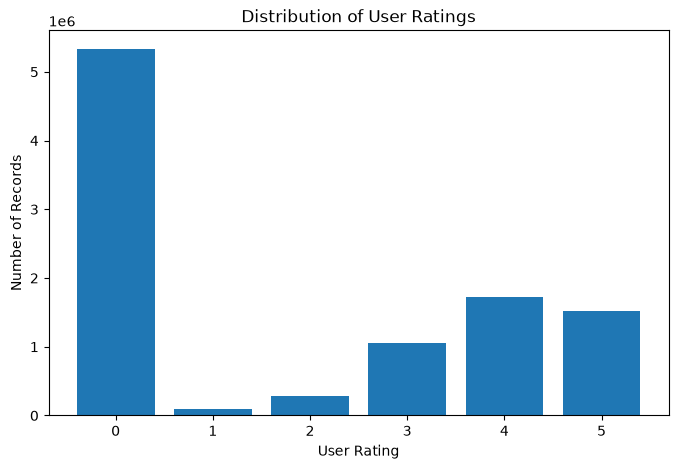

In [9]:
# User rating distribution

rating_counts = df['user_rating'].value_counts().sort_index()

plt.figure(figsize=(8, 5))

plt.bar(rating_counts.index.astype(str), rating_counts.values)

plt.xlabel('User Rating')
plt.ylabel('Number of Records')
plt.title('Distribution of User Ratings')

plt.show()

More than half of the records (~5.5 million) have a user rating of 0, suggesting a substantial amount of unrecorded rating data, which means most users do not leave a rating for books.

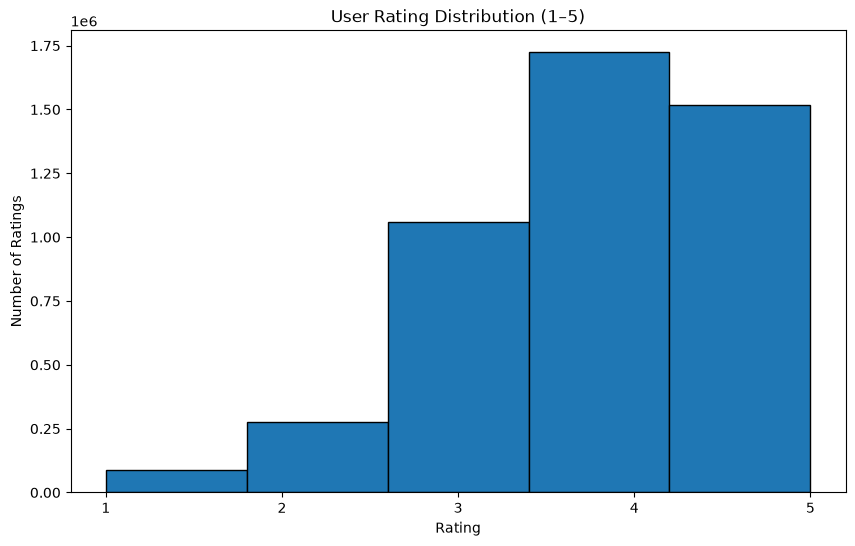

In [10]:
df_rated = df[df['user_rating'] > 0]

plt.figure(figsize=(10, 6))

plt.hist(
    df_rated['user_rating'],
    bins=5,
    edgecolor='black'
)

plt.xlabel('Rating')
plt.ylabel('Number of Ratings')
plt.title('User Rating Distribution (1–5)')
plt.xticks(range(1, 6))

plt.show()

The majority of ratings are 4 and 5, while ratings 1 and 2 are much less frequent.

Rating 4 is the most common.

Since most observations are concentrated towards 4-5, the distribution is left-skewed.

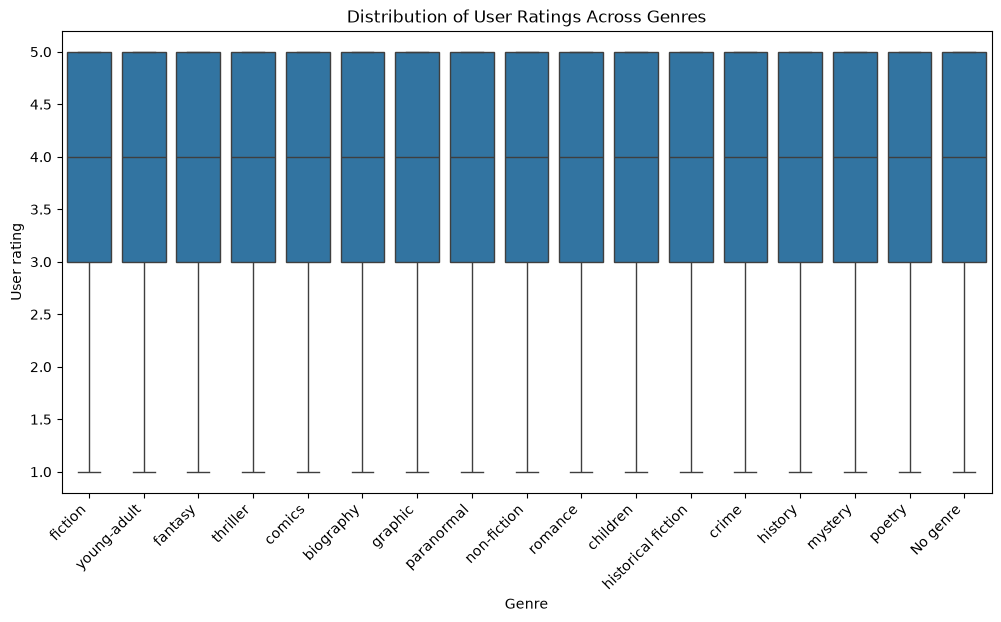

In [11]:
# Distribution of user ratings across genre

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df_rated,
    x='book_genre_1',
    y='user_rating'
)

plt.xticks(rotation=45, ha='right')
plt.xlabel('Genre')
plt.ylabel('User rating')
plt.title('Distribution of User Ratings Across Genres')
plt.show()

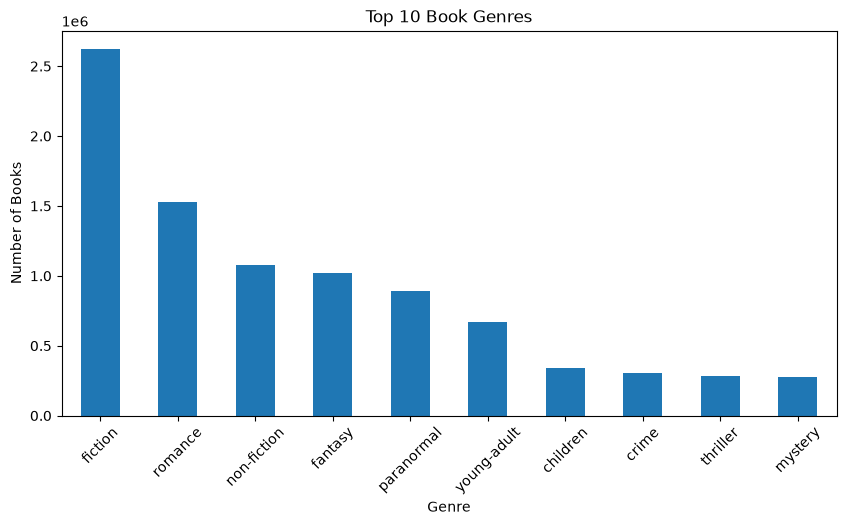

In [16]:
df['book_genre_1'].value_counts().head(10).plot(
    kind='bar',
    figsize=(10,5)
)

plt.xlabel('Genre')
plt.ylabel('Number of Books')
plt.title('Top 10 Book Genres')

plt.xticks(rotation=45)
plt.show()

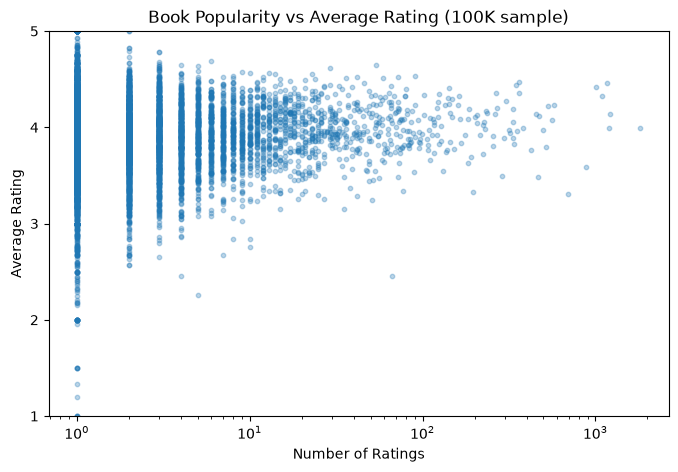

In [12]:
# Book Popularity vs Average Rating

book_stats = df_rated.groupby('book_id').agg(
    rating_count=('user_rating', 'count'),
    average_rating=('book_average_rating', 'first')
).reset_index()

plot_sample = book_stats.sample(
    n=min(10000, len(book_stats)),
    random_state=42
)

plt.figure(figsize=(8,5))

plt.scatter(
    plot_sample['rating_count'],
    plot_sample['average_rating'],
    alpha=0.3,
    s=10
)

plt.xscale('log')
plt.xlabel('Number of Ratings')
plt.ylabel('Average Rating')
plt.title('Book Popularity vs Average Rating (100K sample)')

plt.ylim(1, 5)
plt.yticks(range(1, 6))

plt.show()

Books with few ratings (1 to 10 ratings on the log scale) show extreme rating variance, spanning all the way from 1.0 to 5.0 stars.

As the number of ratings grows past 100 towards 1000, the variance narrows sharply.

Highly popular books maintain strong average scores (approx. 3.5 - 4.5), with very few popular books falling below 3.0.

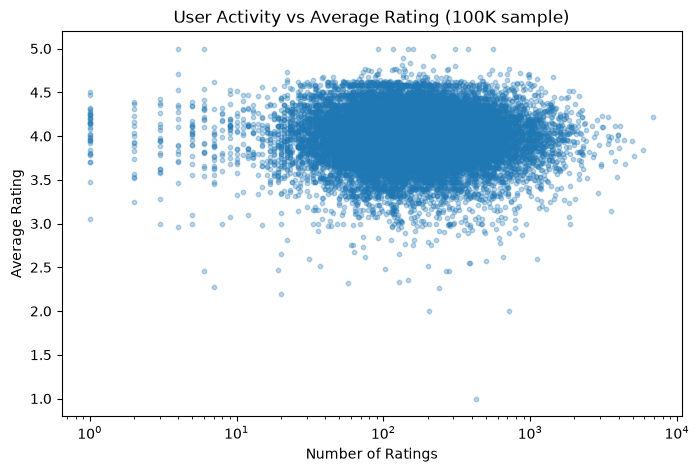

In [13]:
# User Activity vs Average Rating

user_stats = df_rated.groupby('user_id').agg(
    rating_count=('user_rating', 'count'),
    average_rating=('book_average_rating', 'first')
)

plot_sample_2 = user_stats.sample(
    n=min(100000, len(user_stats)),
    random_state=42
)

plt.figure(figsize=(8,5))

plt.scatter(
    user_stats['rating_count'],
    user_stats['average_rating'],
    alpha=0.3,
    s=10
)

plt.xscale('log')
plt.xlabel('Number of Ratings')
plt.ylabel('Average Rating')
plt.title('User Activity vs Average Rating (100K sample)')

plt.show()

Unlike the book popularity plot, the user density is heavily concentrated in the mid-to-high activity region (10 to 1000 ratings per user), peaking around 100 ratings.

The mean rating remains consistently centered around 4.0 stars.

Power (highly-active) users (those with 100 to 1000 ratings) show very few mean scores below 3.0 stars.

Active reviewers do not become overly hyper-critical on average; instead, they consistently rate items positively over time.

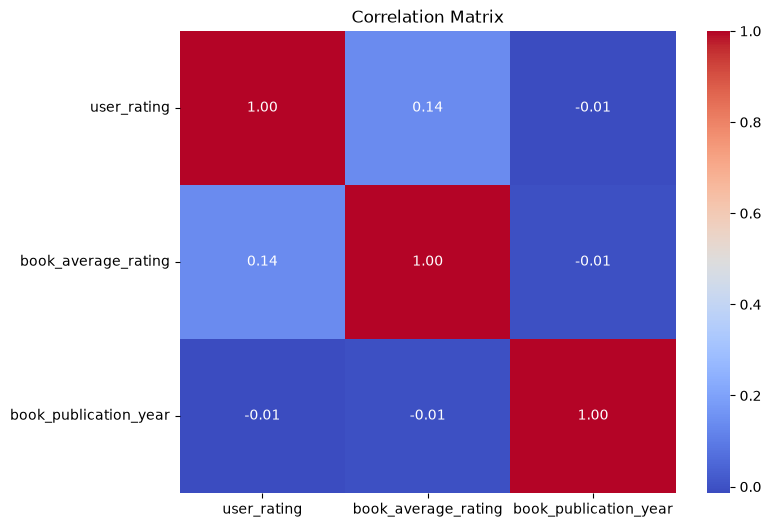

In [14]:
# Correlation Matrix

numeric_cols = df.select_dtypes(include='number').columns

df[
    ['user_rating',
     'book_average_rating',
     'book_publication_year']
].corr()

numeric_cols = [
    'user_rating',
    'book_average_rating',
    'book_publication_year'
]

corr = df[numeric_cols].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Matrix')

plt.show()

In [15]:
The correlation matrix highlights key relationships among individual user ratings, overall book average ratings, and publication years:

Weak-to-Moderate Positive Relationship Between Individual Ratings and Book Average Rating (r = 0.14): A user's rating has a modest positive correlation with a book's overall average rating.
-> Knowing a book's overall average rating gives you almost no ability to predict how an individual user will rate it. Personal preference and variance dominate over consensus quality

No Relationship with Publication Year (r = 0.01 and r = 0.02): Publication year (book_publication_year) shows virtually zero linear correlation with both individual user ratings and overall book average ratings.
-> A book's age or recency has no impact on its quality score or user appreciation—older classics and newly published books perform identically on average

SyntaxError: unterminated string literal (detected at line 4) (3289753771.py, line 4)